## Parallel flow

In [1]:
from langgraph.graph import StateGraph, START, END
from typing import  TypedDict

In [2]:
class BatsmanState(TypedDict):
    runs: int
    balls: int
    fours: int
    sixes: int
    sr: float
    bpb: float
    boundary_percentage: float
    summary: str

In [3]:
def calculate_sr(state:BatsmanState):
    sr = (state['runs']/state['balls'])*100
    return {'sr': round(sr,2)}

In [4]:
def calculate_bpb(state:BatsmanState):
    bpb = state['balls']/(state['sixes']+state['fours'])
    return {'bpb': round(bpb,2)}


In [5]:
def calculate_boundary_percent(state: BatsmanState):

    boundary_percentage = (((state['fours'] * 4) + (state['sixes'] * 6))/state['runs'])*100

    return {'boundary_percentage': boundary_percentage}

In [6]:
def summary(state: BatsmanState):

    summary = f"""
Strike Rate - {state['sr']}
Balls per boundary - {state['bpb']}
Boundary percent - {state['boundary_percentage']}
"""

    return {'summary': summary}

In [8]:
graph = StateGraph(BatsmanState)

graph.add_node('calculate_sr', calculate_sr)
graph.add_node('calculate_bpb', calculate_bpb)
graph.add_node('calculate_boundary_percent', calculate_boundary_percent)
graph.add_node('summary', summary)

graph.add_edge(START, 'calculate_sr')
graph.add_edge(START, 'calculate_bpb')
graph.add_edge(START, 'calculate_boundary_percent')

graph.add_edge('calculate_sr', 'summary')
graph.add_edge('calculate_bpb', 'summary')
graph.add_edge('calculate_boundary_percent', 'summary')

graph.add_edge('summary', END)

workflow = graph.compile()


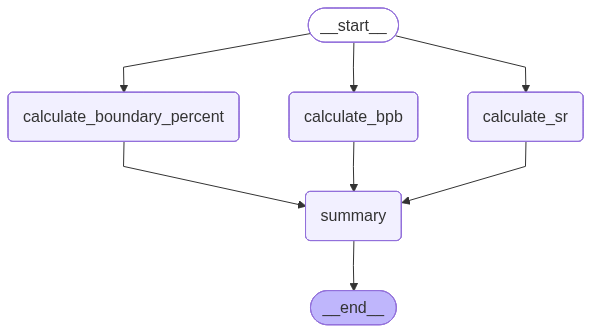

In [9]:
workflow

In [10]:
initial_states= intial_state = {
    'runs': 100,
    'balls': 50,
    'fours': 6,
    'sixes': 4
}

In [11]:
workflow.invoke(initial_states)

{'runs': 100,
 'balls': 50,
 'fours': 6,
 'sixes': 4,
 'sr': 200.0,
 'bpb': 5.0,
 'boundary_percentage': 48.0,
 'summary': '\nStrike Rate - 200.0\nBalls per boundary - 5.0\nBoundary percent - 48.0\n'}

### Parallel Flow using LLM

In [12]:
from langgraph.graph import StateGraph, START, END
from langchain_openai import ChatOpenAI
from dotenv import load_dotenv
from typing import TypedDict, Annotated
from pydantic import BaseModel, Field
import operator


In [13]:
load_dotenv()

True

In [14]:
model = ChatOpenAI(model='gpt-4o-mini')

### Setting Structured Output
Pydantic base model and fields for structured output

In [18]:
class EvaluationSchema(BaseModel):
    feedback: str = Field(description="Detailed Feedback for the essay")
    score: int = Field(description="Score out of 10", ge=0, le=10)

In [19]:
structured_model = model.with_structured_output(EvaluationSchema)

In [20]:
essay = """India in the Age of AI
As the world enters a transformative era defined by artificial intelligence (AI), India stands at a critical juncture — one where it can either emerge as a global leader in AI innovation or risk falling behind in the technology race. The age of AI brings with it immense promise as well as unprecedented challenges, and how India navigates this landscape will shape its socio-economic and geopolitical future.

India's strengths in the AI domain are rooted in its vast pool of skilled engineers, a thriving IT industry, and a growing startup ecosystem. With over 5 million STEM graduates annually and a burgeoning base of AI researchers, India possesses the intellectual capital required to build cutting-edge AI systems. Institutions like IITs, IIITs, and IISc have begun fostering AI research, while private players such as TCS, Infosys, and Wipro are integrating AI into their global services. In 2020, the government launched the National AI Strategy (AI for All) with a focus on inclusive growth, aiming to leverage AI in healthcare, agriculture, education, and smart mobility.

One of the most promising applications of AI in India lies in agriculture, where predictive analytics can guide farmers on optimal sowing times, weather forecasts, and pest control. In healthcare, AI-powered diagnostics can help address India’s doctor-patient ratio crisis, particularly in rural areas. Educational platforms are increasingly using AI to personalize learning paths, while smart governance tools are helping improve public service delivery and fraud detection.

However, the path to AI-led growth is riddled with challenges. Chief among them is the digital divide. While metropolitan cities may embrace AI-driven solutions, rural India continues to struggle with basic internet access and digital literacy. The risk of job displacement due to automation also looms large, especially for low-skilled workers. Without effective skilling and re-skilling programs, AI could exacerbate existing socio-economic inequalities.

Another pressing concern is data privacy and ethics. As AI systems rely heavily on vast datasets, ensuring that personal data is used transparently and responsibly becomes vital. India is still shaping its data protection laws, and in the absence of a strong regulatory framework, AI systems may risk misuse or bias.

To harness AI responsibly, India must adopt a multi-stakeholder approach involving the government, academia, industry, and civil society. Policies should promote open datasets, encourage responsible innovation, and ensure ethical AI practices. There is also a need for international collaboration, particularly with countries leading in AI research, to gain strategic advantage and ensure interoperability in global systems.

India’s demographic dividend, when paired with responsible AI adoption, can unlock massive economic growth, improve governance, and uplift marginalized communities. But this vision will only materialize if AI is seen not merely as a tool for automation, but as an enabler of human-centered development.

In conclusion, India in the age of AI is a story in the making — one of opportunity, responsibility, and transformation. The decisions we make today will not just determine India’s AI trajectory, but also its future as an inclusive, equitable, and innovation-driven society."""

In [21]:
prompt = f'Evaluate the language quality of the following essay and provide a feedback and assign a score out of 10 \n {essay}'
output  = structured_model.invoke(prompt)

In [22]:
output

EvaluationSchema(feedback="The essay provides a coherent and insightful analysis of India's position in the age of AI. The structure is well-organized, with a clear introduction, detailed body paragraphs discussing strengths and challenges, and a strong conclusion that encapsulates the key points. The vocabulary is appropriate for the topic, and the language is generally formal and engaging. However, some sentences could be more concise to enhance readability, and the argument could benefit from more specific examples or data to support claims, particularly regarding the digital divide and job displacement. Overall, it demonstrates a good command of language and critical thinking, but there is some room for improvement in clarity and specificity.", score=8)

In [23]:
output.score

8

In [24]:
###
class EssayState(TypedDict):
    essay:str
    language_feedback: str
    analysis_feedback: str
    clarity_feedback: str
    overall_feedback: str
    individual_scores : Annotated[list[int], operator.add] ## For merging the out from different nodes
    average_score: float



In [26]:
def evaluate_language(state: EssayState)-> EssayState:
    essay = state['essay']
    prompt = f"""
    Evaluate the language quality of the following essay and provide a feedback and assign a score out of 10 \n {essay}
    """
    output = structured_model.invoke(prompt)

    return {'language_feedback': output.feedback, 'individual_scores': [output.score]}


In [27]:
def evaluate_analysis(state: EssayState)-> EssayState:
    essay = state['essay']
    prompt = f"""
    Evaluate the analytical depth of the following essay and provide a feedback and assign a score out of 10 \n {essay}
    """
    output = structured_model.invoke(prompt)
    return {'analysis_feedback': output.feedback, 'individual_scores': [output.score]}

In [28]:
def evaluate_clarity(state: EssayState)-> EssayState:
    essay = state['essay']
    prompt = f"""
    Evaluate the clarity of the following essay and provide a feedback and assign a score out of 10 \n {essay}
    """
    output = structured_model.invoke(prompt)

    return {'clarity_feedback': output.feedback, 'individual_scores': [output.score]}

In [29]:
def final_evaluation(state: EssayState)-> EssayState:
    essay = state['essay']

    language_feedback = state['language_feedback']
    analysis_feedback = state['analysis_feedback']
    clarity_feedback = state['clarity_feedback']

    prompt = f"""
    Based on the following feedback, provide an overall evaluation of the essay.
    essay : {essay}
    Language Feedback: {language_feedback}
    Analysis Feedback: {analysis_feedback}
    Clarity Feedback: {clarity_feedback}"""

    individual_scores = state['individual_scores']

    overall_feedback = model.invoke(prompt).content

    average_score = sum(individual_scores)/len(individual_scores)



    return {'overall_feedback': overall_feedback, 'average_score': average_score}

In [30]:
graph = StateGraph(EssayState)
graph.add_node('evaluate_language', evaluate_language)
graph.add_node('evaluate_analysis', evaluate_analysis)
graph.add_node('evaluate_clarity', evaluate_clarity)
graph.add_node('final_evaluation', final_evaluation)

graph.add_edge(START, 'evaluate_language')
graph.add_edge(START, 'evaluate_analysis')
graph.add_edge(START, 'evaluate_clarity')

graph.add_edge('evaluate_language', 'final_evaluation')
graph.add_edge('evaluate_analysis', 'final_evaluation')
graph.add_edge('evaluate_clarity', 'final_evaluation')

graph.add_edge('final_evaluation', END)

workflow = graph.compile()

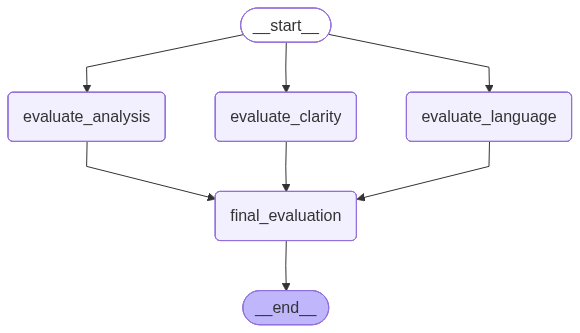

In [31]:
workflow

In [32]:
essay_bad = f"""
Humanity and AI
Humanity is basicly when people do stuff. but now we have AI (artifishel intellegence) which is like a robot brain in a box. some peaple say its good but some say its spooky and might take over the world like in that movie with the shiny skeleton man.

why ai is weird
firstly, ai dont have feelings. if i trip and fall, my mom says "oh no are u okay?" but if i tell a computer i fell it just says "Error 404: grass not found." this is because code is just math and math dont have a heart.

robots dont cry

they dont eat pizza (sad!)

they just beep and boop all day long.

the futur of us
computors are geting smarter then us at chess and spelling (not me tho). if we let them do everything, then humans will just sit on the couch and become blobs like in that space movie with the trash robot. we need to be carefull because if the wifi goes out, then the ai dies and then what? we wont know how to cook a egg without asking Siri.
"""

In [33]:
initial_states = {'essay':essay}

final_state = workflow.invoke(initial_states)

In [34]:
final_state['overall_feedback']

'**Overall Evaluation of the Essay: "Humanity and AI"**\n\nThe essay "Humanity and AI" presents a creative and humorous take on the complex subject of artificial intelligence, but it ultimately falls short in several key areas. While the intention to engage readers with relatable examples and a light-hearted tone is commendable, significant language, structural, and clarity issues hinder the effectiveness of the argument being presented.\n\n**Language and Grammar**: The essay contains multiple spelling and grammatical errors (e.g., "basicly," "artifishel intellegence," "geting," "computors"), which detract from its professionalism and readability. The informal language, including colloquialisms such as "stuff" and "beep and boop," while potentially relatable, undermines the seriousness of the subject matter. A more polished approach would enhance the essay\'s credibility and help convey the points more effectively.\n\n**Analysis and Depth**: The essay lacks analytical depth and primari

In [35]:
final_state['average_score']

3.6666666666666665

In [1]:
print("hello")

hello
